# 06 — Prescriptive Analytics + Forecast (Tahap 5)

## Tujuan
Menjawab **"apa yang sebaiknya dilakukan?"** dengan kerangka slide kuliah:
**Prediksi (+ interval keyakinan) + Aturan bisnis dan batasan → Tindakan yang direkomendasikan** (opsi tindakan, tabel hasil optimasi, simulasi *what-if*, dampak yang diperkirakan).

1. **Investor (sudut pandang utama):** pinjaman mana yang didanai di bawah batas anggaran, risiko, dan diversifikasi (strategi S0–S5; S3 = optimasi berbatas).
2. **Platform pemberi pinjaman (skenario tambahan):** kebijakan persetujuan (batas risiko `τ`) dan penetapan bunga impas (*breakeven pricing*).
3. **Forecast ringan:** deret bulanan volume pinjaman dan arus default baru dengan interval prediksi, dihubungkan dengan keputusan investor.

## Input / Output
- **Input:** `data/processed/predictions_default12m.parquet` (`p_calibrated`, LGBM-A terkalibrasi), `predictions_return_ratio.parquet` (`pred_return_ratio`), `bondora_clean.parquet`, serta parameter di `src/config.py`.
- **Output:** tabel `reports/tables/06_*.csv`, grafik `reports/figures/06_*.png`. Semuanya dihasilkan satu perintah: `python -m src.analysis.prescriptive_run`.

> **Aturan kerja:** parameter bisnis ditetapkan **sebelum** backtest dan tidak disetel berdasarkan hasil uji. Angka *ex-ante* (berbasis prediksi model) dan *ex-post* (berbasis hasil aktual `default_12m`) selalu ditampilkan berdampingan. Semua rekomendasi bersifat **dukungan keputusan di bawah asumsi**, bukan kepastian.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

project_root = Path.cwd().resolve()
if project_root.name == "notebooks":
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import src.config as config

pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 80)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

T = config.TABLES_DIR
F = config.FIGURES_DIR
meta = json.loads((T / "06_run_meta.json").read_text(encoding="utf-8"))
print(f"Project root : {config.PROJECT_ROOT}")
print(f"Random seed  : {config.RANDOM_SEED}")

Project root : D:\tugas_3_pemodelan_data\bondora-analytics
Random seed  : 42


## 1. Preflight dan Himpunan Peluang (*Opportunity Set*)

Himpunan peluang untuk backtest adalah pinjaman pada split **uji** (`LoanDate` 2019-07-01 s.d. 2020-07-20) yang hasil 12 bulannya sudah teramati. Model, kalibrator, dan parameter dilatih/ditetapkan **tanpa** data ini, sehingga backtest tidak bocor.

Fakta Tahap 4 yang menjadi dasar kehati-hatian: probabilitas `p_calibrated` rata-rata **≈ 33%** padahal default 12 bulan aktual **26,77%** (dilebih-lebihkan ± 6 poin persentase), dan daya urut dalam-negara lemah (Finlandia AUC 0,55; Spanyol 0,58). Model regresi `return_ratio` lemah (R² uji 0,025), sehingga hanya dipakai sebagai sinyal **urutan** (strategi S4).

In [2]:
pre = meta["preflight"]
for k, v in pre.items():
    print(f"{k:28s}: {v}")
print("Cek silang model regresi tersimpan vs predictions_return_ratio:", meta["return_ratio_crosscheck"])

assert pre["n_pred_default12m"] == 148_369 and pre["n_pred_default12m_test"] == 54_283
assert pre["n_pred_return_ratio"] == 113_560 and pre["p_calibrated_nan"] == 0
assert 0.0 <= pre["p_calibrated_min"] and pre["p_calibrated_max"] <= 1.0

opp = meta["opportunity_set"]
print()
print(f"Himpunan peluang (uji)          : n = {opp['n']:,}")
print(f"Rata-rata p_calibrated          : {opp['p_mean']:.4f}")
print(f"Default 12 bulan aktual         : {opp['default_rate_actual']:.4f}")
print(f"Rata-rata interest12_frac       : {opp['interest12_frac_mean']:.4f}")
print(f"Rata-rata u ex-ante / ex-post   : {opp['u_exante_mean']:.4f} / {opp['u_expost_mean']:.4f}")

n_pred_default12m           : 148369
n_pred_default12m_test      : 54283
n_pred_return_ratio         : 113560
p_calibrated_min            : 0.0
p_calibrated_max            : 0.8
p_calibrated_nan            : 0
test_loandate_min           : 2019-07-01
test_loandate_max           : 2020-07-20
Cek silang model regresi tersimpan vs predictions_return_ratio: {'n': 31175, 'max_abs_diff': 0.0}

Himpunan peluang (uji)          : n = 54,283
Rata-rata p_calibrated          : 0.3296
Default 12 bulan aktual         : 0.2677
Rata-rata interest12_frac       : 0.3336
Rata-rata u ex-ante / ex-post   : -0.0373 / 0.0235


## 2. Parameter dan Asumsi (`06_params.csv`)

Seluruh parameter bisnis dan asumsi ditulis eksplisit di `src/config.py` dan dirangkum di tabel berikut (tidak ada angka asumsi tersembunyi dalam kode). Semua batas berupa **proporsi eksposur** (jumlah EUR yang didanai). Karena tiket sama untuk semua pinjaman, proporsi eksposur sama dengan proporsi jumlah pinjaman.

In [3]:
params = pd.read_csv(T / "06_params.csv")
display(params)

,parameter,nilai,alasan
0,TICKET_EUR,50.0,Nominal yang didanai per pinjaman; investor me...
1,BUDGET_EUR,250000.0,Anggaran investor; setara sekitar 5.000 pinjam...
2,N_PINJAMAN,5000,Jumlah pinjaman yang didanai = BUDGET_EUR / TI...
3,MAX_AVG_P,0.2,Batas rata-rata p_calibrated portofolio (seler...
4,MAX_SHARE_COUNTRY,0.7,"Batas konsentrasi per negara (diversifikasi, b..."
5,MAX_SHARE_WORST_RATINGS,0.25,Batas eksposur rating F dan HR (rating tersedi...
6,MAX_SHARE_TENOR60,0.7,Batas eksposur tenor 60 bulan (risiko jangka p...
7,MIN_LOANS,2000,Jumlah pinjaman minimum untuk diversifikasi (a...
8,PD_STRESS_GRID,-20%; +0%; +20%; +50%,Pengali pada p untuk simulasi what-if.
9,LGD_SHIFT_GRID,-0.10; +0.00; +0.10,Pergeseran kerugian saat default (pecahan poko...


## 3. Fungsi Ekonomi (Langkah 2)

**Bunga 12 bulan jika pinjaman lancar** (pecahan dari pokok), untuk pinjaman anuitas dengan bunga tahunan `Interest` (%) dan tenor `n` bulan:

- `i = Interest / 100 / 12`, cicilan `PMT = A·i / (1 − (1+i)^−n)` (jika `i = 0`, `PMT = A/n`), horizon `m = min(12, n)`.
- `saldo_m = A·(1+i)^m − PMT·((1+i)^m − 1)/i`, bunga dibayar `= m·PMT − (A − saldo_m)`, `interest12_frac = bunga / A`.

**Kerugian saat default** `L = 1 − rata-rata(PrincipalPaymentsMade / Amount)` pada pinjaman **latih dan validasi** dengan `default_12m == 1`.

**Keuntungan per EUR yang diinvestasikan selama 12 bulan:**

- *Ex-ante:* `u_i = (1 − p_i)·interest12_frac_i − p_i·L`
- *Ex-post:* `u_i_real = (1 − d_i)·interest12_frac_i − d_i·L`, dengan `d_i = default_12m` aktual.
- Keuntungan portofolio `Σ ticket_i·u_i`; `ROI = keuntungan ÷ total investasi`.

Asumsi: bunga sederhana tanpa reinvestasi, tanpa biaya platform, kerugian konstan `L`. Angka `L` bersifat **konservatif** (penagihan pinjaman yang baru default masih berjalan) dan bunga yang diterima sebelum default diabaikan.

In [4]:
lgd = meta["lgd"]
print("Estimasi L (hanya data latih + validasi, default_12m == 1)")
print(f"  n                  : {lgd['n']:,}")
print(f"  L                  : {lgd['L']:.4f}  (CI bootstrap 95%: {lgd['ci_low']:.4f} - {lgd['ci_high']:.4f})")
print(f"  pemulihan rata2    : {lgd['recovery_mean']:.4f}, median {lgd['recovery_median']:.4f}")
print(f"  pemulihan p10/p90  : {lgd['recovery_p10']:.4f} / {lgd['recovery_p90']:.4f}")
print(f"  share pemulihan 0  : {lgd['share_zero_recovery']:.4f}")

assert lgd["n"] == 28_585 and round(lgd["L"], 3) == 0.731

Estimasi L (hanya data latih + validasi, default_12m == 1)
  n                  : 28,585
  L                  : 0.7311  (CI bootstrap 95%: 0.7274 - 0.7348)
  pemulihan rata2    : 0.2689, median 0.0950
  pemulihan p10/p90  : 0.0000 / 0.8456
  share pemulihan 0  : 0.1134


### 3.1 Validasi `interest12_frac` terhadap `MonthlyPayment`

`PMT × Amount` dibandingkan dengan kolom `MonthlyPayment` aktual. Korelasi tinggi, tetapi **selisih tidak kecil dan sistematis**, bukan derau acak. Tabel kedua menghitung "bunga implisit" (bunga tahunan yang mereproduksi `MonthlyPayment` pada rumus anuitas) menurut negara dan rating.

In [5]:
val = pd.read_csv(T / "06_interest_validation.csv")
display(val)
seg = pd.read_csv(T / "06_interest_validation_segments.csv")
display(seg)

assert round(val.loc[0, "korelasi"], 3) == 0.962
assert round(val.loc[0, "median_selisih_relatif_abs"], 3) == 0.079
assert round(val.loc[0, "share_dalam_5persen"], 3) == 0.253

,n_dibandingkan,korelasi,median_selisih_relatif,median_selisih_relatif_abs,p95_selisih_relatif_abs,share_dalam_5persen
0,54283,0.9619,-0.0294,0.0786,0.1864,0.2532


,dimensi,segmen,n,interest_median,r_implisit_median,selisih_pp_median,selisih_rel_pmt_median
0,Country,EE,27976,25.2700,29.6513,4.9042,-0.0668
1,Country,ES,12662,58.0900,60.6347,-4.1960,0.0514
2,Country,FI,13645,36.9000,32.5451,-5.2576,0.0809
3,Rating,A,2030,11.7500,17.9010,6.2065,-0.0906
4,Rating,AA,3550,8.9700,15.4520,6.4636,-0.0941
5,Rating,B,3878,16.0300,21.7481,5.5711,-0.0868
6,Rating,C,7303,22.8600,27.4177,4.0138,-0.0596
7,Rating,D,10839,32.0800,35.0924,2.2943,-0.0334
8,Rating,E,15922,38.9550,33.5974,-5.0562,0.0747
9,Rating,F,9608,61.8600,60.6347,-7.7135,0.0950


**Interpretasi.** Korelasi `PMT × Amount` dengan `MonthlyPayment` = **0,962**, tetapi median selisih relatif absolut **7,9%** dan hanya **25,3%** pinjaman berada dalam ±5%. Pola selisihnya sistematis menurut rating: untuk rating baik (AA, A, B) bunga implisit lebih **tinggi** 5,6–6,5 poin daripada `Interest`, sedangkan untuk rating buruk (E, F, HR) lebih **rendah** (HR: −14,0 poin). Dugaan yang konsisten dengan pola ini adalah bahwa `MonthlyPayment` mencerminkan biaya total peminjam (termasuk biaya/komisi dan batas bunga efektif) sehingga distribusinya lebih sempit daripada `Interest`. **Dugaan ini belum terverifikasi** dengan dokumentasi sumber data.

Konsekuensi: pendapatan bunga yang dipakai (`Interest` sebagai imbal hasil investor) mengandung **ketidakpastian definisi**. Pengaruhnya pada keputusan diuji sebagai uji ketahanan di Bagian 6.2, dan dicantumkan sebagai keterbatasan.

## 4. Strategi Investor dan Tabel Hasil Optimasi (Langkah 3–4)

Anggaran `BUDGET_EUR = 250.000` dan tiket `TICKET_EUR = 50` → `N = 5.000` pinjaman.

| Kode | Strategi | Aturan |
|---|---|---|
| S0 | Acak (baseline) | `N` pinjaman acak, rata-rata 100 undian (`RANDOM_SEED`) |
| S1 | Ikuti rating Bondora | `N` pinjaman dengan rating terbaik (AA → HR), pemecah seri acak |
| S2 | Risiko terendah | `N` pinjaman dengan `p_calibrated` terendah, **tanpa** batas konsentrasi |
| S3 | **Optimasi berbatas (kandidat rekomendasi)** | Maksimalkan `Σ u_i` (ex-ante) di bawah semua batasan |
| S4 | Peringkat pengembalian | `N` pinjaman dengan `pred_return_ratio` tertinggi |
| S5 | Imbal hasil tertinggi (peringatan) | `N` pinjaman dengan `Interest` tertinggi (strategi naif pengejar bunga) |

**Optimasi S3:** variabel keputusan `x_i ∈ {0,1}`; tujuan `maks Σ TICKET·u_i·x_i`; kendala: `Σ x_i = N`, `Σ x_i ≥ MIN_LOANS`, `Σ (p_i − MAX_AVG_P)·x_i ≤ 0`, eksposur tiap negara ≤ `MAX_SHARE_COUNTRY`, rating F+HR ≤ `MAX_SHARE_WORST_RATINGS`, tenor 60 bulan ≤ `MAX_SHARE_TENOR60` (semua linear dalam `x_i`).

> **Catatan solver (deviasi dari rencana).** `pulp` 4.x yang terpasang tidak lagi menyertakan CBC (`pulp.listSolvers(onlyAvailable=True)` kosong). Sebagai gantinya dipakai **HiGHS lewat `scipy.optimize`**: relaksasi LP diselesaikan lebih dulu; bila solusinya integral maka ia juga optimal untuk masalah biner. Bila ada variabel pecahan, variabel yang sudah 0/1 dikunci dan MILP kecil atas variabel pecahan diselesaikan (gap ke batas LP dilaporkan). Penyelesaian biner langsung atas 54.283 variabel melewati batas waktu 3 menit, sehingga tidak dipakai. Tidak ada pembatasan kandidat (semua 54.283 pinjaman ikut dioptimasi).

In [6]:
res = pd.read_csv(T / "06_strategy_results.csv")
cols = ["opsi", "deskripsi", "n_pinjaman", "total_investasi_eur", "p_rata2_exante",
        "default_rate_expost", "default_rate_ci_low", "default_rate_ci_high",
        "profit_exante_eur", "roi_exante", "profit_expost_eur", "profit_expost_ci_low", "profit_expost_ci_high",
        "roi_expost", "roi_expost_ci_low", "roi_expost_ci_high", "memenuhi_batasan", "rekomendasi"]
display(res[cols])

conc = ["opsi", "share_country_maks", "country_maks", "share_rating_FHR", "share_tenor60",
        "ok_min_loans", "ok_avg_p", "ok_country", "ok_rating_FHR", "ok_tenor60", "memenuhi_batasan"]
print("Konsentrasi dan pemeriksaan tiap batasan:")
display(res[conc])

s = res.set_index("opsi")
assert s.loc["S3", "rekomendasi"] == "Ya" and (res["rekomendasi"] == "Ya").sum() == 1
assert bool(s.loc["S3", "memenuhi_batasan"]) and not s.drop("S3")["memenuhi_batasan"].any()
assert round(s.loc["S3", "roi_exante"], 4) == 0.2094 and round(s.loc["S3", "roi_expost"], 4) == 0.1901
assert round(s.loc["S5", "default_rate_expost"], 3) == 0.567

,opsi,deskripsi,n_pinjaman,total_investasi_eur,p_rata2_exante,default_rate_expost,default_rate_ci_low,default_rate_ci_high,profit_exante_eur,roi_exante,profit_expost_eur,profit_expost_ci_low,profit_expost_ci_high,roi_expost,roi_expost_ci_low,roi_expost_ci_high,memenuhi_batasan,rekomendasi
0,S0,"Acak (baseline), rata-rata 100 undian",5000,"250,000.0000",0.3292,0.2678,0.2558,0.2787,"-9,264.1256",-0.0371,"5,827.3312","2,839.7461","8,935.0845",0.0233,0.0114,0.0357,False,Tidak
1,S1,Ikuti rating Bondora (AA -> HR),5000,"250,000.0000",0.1515,0.0870,0.0795,0.0951,"-9,698.6542",-0.0388,"3,425.4903","1,643.6046","5,054.0244",0.0137,0.0066,0.0202,False,Tidak
2,S2,"Risiko terendah (p_calibrated terendah, tanpa ...",5000,"250,000.0000",0.0561,0.0512,0.0454,0.0577,"35,699.7920",0.1428,"36,327.4764","34,483.7568","37,709.1316",0.1453,0.1379,0.1508,False,Tidak
3,S3,Optimasi berbatas (maksimalkan profit ex-ante ...,5000,"250,000.0000",0.1791,0.1924,0.1817,0.2036,"52,351.4743",0.2094,"47,520.2426","44,315.1079","50,640.9899",0.1901,0.1773,0.2026,True,Ya
4,S4,Peringkat pengembalian (pred_return_ratio tert...,5000,"250,000.0000",0.1364,0.0932,0.0855,0.1016,"22,305.3539",0.0892,"32,240.9435","30,323.3506","34,253.9513",0.1290,0.1213,0.1370,False,Tidak
5,S5,Imbal hasil tertinggi (Interest tertinggi; str...,5000,"250,000.0000",0.5540,0.5670,0.5532,0.5807,"-19,235.5903",-0.0769,"-24,183.5149","-29,901.0123","-19,567.1943",-0.0967,-0.1196,-0.0783,False,Tidak


Konsentrasi dan pemeriksaan tiap batasan:


,opsi,share_country_maks,country_maks,share_rating_FHR,share_tenor60,ok_min_loans,ok_avg_p,ok_country,ok_rating_FHR,ok_tenor60,memenuhi_batasan
0,S0,0.5166,EE,0.1989,0.5586,True,False,True,True,True,False
1,S1,1.0000,EE,0.0000,0.4312,True,True,False,True,True,False
2,S2,1.0000,EE,0.0008,0.4084,True,True,False,True,True,False
3,S3,0.7000,EE,0.2294,0.5920,True,True,True,True,True,True
4,S4,0.9832,EE,0.0148,0.2100,True,True,False,True,True,False
5,S5,1.0000,ES,0.9998,0.8676,True,False,False,False,False,False


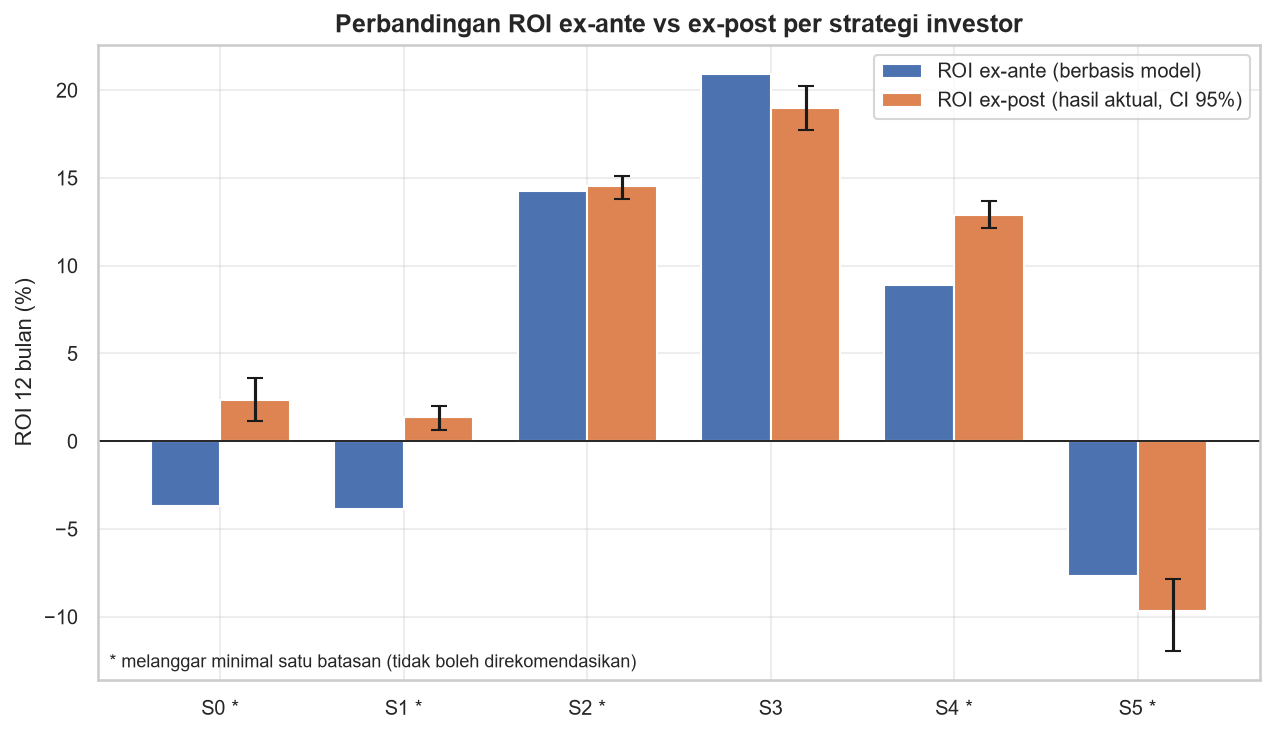

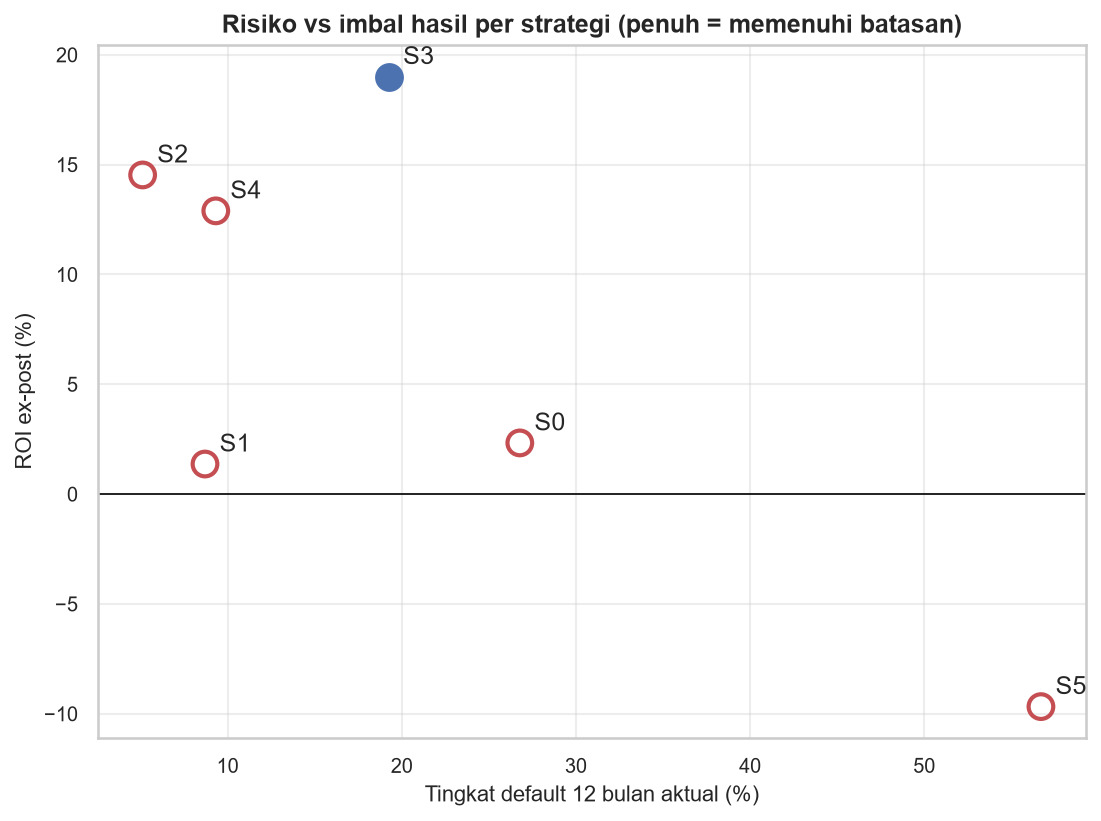

In [7]:
display(Image(filename=str(F / "06_strategy_comparison.png")))
display(Image(filename=str(F / "06_strategy_risk_return.png")))

**Pembacaan tabel hasil optimasi (berdasarkan asumsi di atas).**

- **S3 adalah satu-satunya opsi yang memenuhi seluruh batasan** dan memberi profit ex-ante tertinggi di antara opsi yang patuh: ROI ex-ante **20,94%** (profit 52.351 EUR) dan ROI ex-post **19,01%** (profit 47.520 EUR; CI bootstrap 95% profit 44.315–50.641 EUR). Tingkat default aktual portofolio S3 **19,24%** (CI Wilson 18,17–20,36%).
- **S2 (risiko terendah)** memberi ROI ex-ante 14,28% dan ex-post 14,53% dengan default aktual hanya 5,12%, tetapi **melanggar batas negara** (100% Estonia) sehingga **tidak boleh direkomendasikan**, seberapa pun menariknya. S4 dan S1 juga melanggar batas negara (masing-masing 98,3% dan 100% Estonia).
- **S5 (pengejar bunga)** adalah peringatan: p rata-rata 0,554, default aktual **56,70%** (CI Wilson 55,32–58,07%), ROI ex-post **−9,67%** (ex-ante −7,69%). Bunga tinggi terkompensasi lebih dari penuh oleh gagal bayar; portofolio ini juga melanggar batas rata-rata `p`, rating F+HR (99,98%), dan tenor 60 bulan.
- **S0 dan S1** memberi ROI ex-ante negatif (−3,71% dan −3,88%) tetapi ROI ex-post sedikit positif (+2,33% dan +1,37%), alasan selisih dijelaskan di Bagian 6.

## 5. Portofolio S3: Solver, Kendala yang Mengikat, dan Komposisi

In [8]:
sol = meta["s3_solver"]
for k in ["status", "objective_sum_u", "n_variables", "pool_size", "n_fractional", "all_constraints_ok", "n_selected", "solver"]:
    print(f"{k:20s}: {sol[k]}")
print("Jumlah kandidat dibatasi (pool)? ->", "tidak, seluruh peluang dipakai" if sol["pool_size"] is None else sol["pool_size"])

cons = pd.read_csv(T / "06_s3_constraints.csv")
display(cons)
print("Kendala yang MENGIKAT (slack <= 0,1% dari N):")
display(cons.loc[cons["mengikat"], ["kendala", "lhs", "batas_atas", "batas_bawah", "slack_normal"]])

assert sol["all_constraints_ok"] and sol["n_selected"] == 5_000 and sol["n_variables"] == 54_283
assert cons["terpenuhi"].all()

status              : Optimal (relaksasi LP bersifat integral)
objective_sum_u     : 1047.0294865312012
n_variables         : 54283
pool_size           : None
n_fractional        : 0
all_constraints_ok  : True
n_selected          : 5000
solver              : HiGHS via scipy.optimize.linprog/milp (LP dulu, lalu MILP sisa); pulp 4.x tidak menyertakan CBC
Jumlah kandidat dibatasi (pool)? -> tidak, seluruh peluang dipakai


,kendala,lhs,batas_bawah,batas_atas,slack_normal,mengikat,terpenuhi
0,anggaran: jumlah pinjaman = N,"5,000.0000","5,000.0000","5,000.0000",0.0000,True,True
1,jumlah pinjaman >= MIN_LOANS,"5,000.0000","2,000.0000",NaN,0.6000,False,True
2,rata-rata p <= MAX_AVG_P,-104.6970,NaN,0.0000,0.0209,False,True
3,eksposur negara ES <= MAX_SHARE_COUNTRY,"1,081.0000",NaN,"3,500.0000",0.4838,False,True
4,eksposur negara EE <= MAX_SHARE_COUNTRY,"3,500.0000",NaN,"3,500.0000",0.0000,True,True
5,eksposur negara FI <= MAX_SHARE_COUNTRY,419.0000,NaN,"3,500.0000",0.6162,False,True
6,eksposur rating F+HR <= MAX_SHARE_WORST_RATINGS,"1,147.0000",NaN,"1,250.0000",0.0206,False,True
7,eksposur tenor 60 bulan <= MAX_SHARE_TENOR60,"2,960.0000",NaN,"3,500.0000",0.1080,False,True


Kendala yang MENGIKAT (slack <= 0,1% dari N):


,kendala,lhs,batas_atas,batas_bawah,slack_normal
0,anggaran: jumlah pinjaman = N,"5,000.0000","5,000.0000","5,000.0000",0.0000
4,eksposur negara EE <= MAX_SHARE_COUNTRY,"3,500.0000","3,500.0000",NaN,0.0000


In [9]:
comp = pd.read_csv(T / "06_s3_composition.csv")
for dim in ["Country", "Rating", "Tenor"]:
    print(f"Komposisi S3 menurut {dim}")
    display(comp[comp["dimensi"] == dim].drop(columns="dimensi"))

Komposisi S3 menurut Country


,segmen,n_peluang,share_peluang,n_S3,share_S3,p_rata2_S3,default_rate_expost_S3
0,EE,27976,0.5154,3500,0.7000,0.1050,0.1137
1,ES,12662,0.2333,1081,0.2162,0.3808,0.4570
2,FI,13645,0.2514,419,0.0838,0.2775,0.1671


Komposisi S3 menurut Rating


,segmen,n_peluang,share_peluang,n_S3,share_S3,p_rata2_S3,default_rate_expost_S3
3,A,2030,0.0374,0,0.0000,NaN,NaN
4,AA,3550,0.0654,0,0.0000,NaN,NaN
5,B,3878,0.0714,2,0.0004,0.0000,0.0000
6,C,7303,0.1345,250,0.0500,0.0466,0.0160
7,D,10839,0.1997,1658,0.3316,0.0865,0.0911
8,E,15922,0.2933,1943,0.3886,0.1604,0.1513
9,F,9608,0.1770,1048,0.2096,0.3724,0.4513
10,HR,1153,0.0212,99,0.0198,0.3858,0.4040


Komposisi S3 menurut Tenor


,segmen,n_peluang,share_peluang,n_S3,share_S3,p_rata2_S3,default_rate_expost_S3
11,13-24,1765,0.0325,257,0.0514,0.0708,0.0506
12,25-36,18539,0.3415,1441,0.2882,0.1865,0.1999
13,37-48,2549,0.0470,309,0.0618,0.1812,0.1359
14,49-59,51,0.0009,30,0.0060,0.1173,0.0333
15,60,30312,0.5584,2960,0.5920,0.1851,0.2088
16,<=12,1067,0.0197,3,0.0006,0.3161,0.0000


**Kendala yang mengikat dan komposisi.**

- Kendala yang **mengikat**: anggaran (`Σ x = N = 5.000`) dan **batas negara Estonia** (3.500 pinjaman = 70,0%). Kendala yang **hampir mengikat**: rating F+HR (22,94% dari batas 25%) dan rata-rata `p` (0,179 dari batas 0,20). Tenor 60 bulan (59,2% dari batas 70%) dan `MIN_LOANS` (5.000 vs 2.000) tidak mengikat.
- Komposisi negara: Estonia 70,0%, Spanyol 21,6%, Finlandia 8,4%. Rating: D 33,2%, E 38,9%, F 21,0%, C 5,0%, HR 2,0%; tidak ada rating AA dan A (kemungkinan karena bunganya terlalu rendah untuk mengungguli pinjaman berisiko menengah dengan `p` rendah di dalam batasan ini; sebab ini tidak diuji terpisah).
- Catatan kehati-hatian: pada portofolio S3, pinjaman Spanyol memiliki default aktual 45,7% dibandingkan `p` rata-rata 0,381, sedangkan Estonia 11,4% vs 0,105. Daya urut dalam-negara yang lemah (Tahap 4) berarti keunggulan S3 sebagian bersumber dari perbedaan antar-negara, bukan hanya seleksi dalam negara.
- **Atribut sensitif:** `Gender` tidak dipakai. `Country` hanya berperan sebagai **batas konsentrasi** (diversifikasi risiko portofolio), bukan alat memperlakukan individu secara berbeda: setiap pinjaman dinilai dari `p` model dan batas konsentrasi dikenakan pada total portofolio, bukan pada pemohon.

## 6. Perbandingan Ex-Ante vs Ex-Post dan Uji Ketahanan

### 6.1 Mengapa ex-ante berbeda dari ex-post?

In [10]:
cmp_ = res[["opsi", "p_rata2_exante", "default_rate_expost", "roi_exante", "roi_expost"]].copy()
cmp_["selisih_p_dikurangi_default"] = cmp_["p_rata2_exante"] - cmp_["default_rate_expost"]
cmp_["selisih_roi_expost_dikurangi_exante"] = cmp_["roi_expost"] - cmp_["roi_exante"]
display(cmp_)

opp_meta = meta["opportunity_set"]
gap_p = opp_meta["p_mean"] - opp_meta["default_rate_actual"]
print(f"Seluruh himpunan peluang: p rata2 {opp_meta['p_mean']:.4f} vs default aktual {opp_meta['default_rate_actual']:.4f} -> p dilebihkan {gap_p*100:.2f} poin")
print(f"u ex-ante rata2 {opp_meta['u_exante_mean']:.4f} vs u ex-post rata2 {opp_meta['u_expost_mean']:.4f} -> selisih {(opp_meta['u_expost_mean']-opp_meta['u_exante_mean']):.4f}")
print(f"Perkiraan kasar: selisih p x (bunga + L) = {gap_p:.4f} x ({opp_meta['interest12_frac_mean']:.4f} + {lgd['L']:.4f}) = {gap_p*(opp_meta['interest12_frac_mean']+lgd['L']):.4f}")

,opsi,p_rata2_exante,default_rate_expost,roi_exante,roi_expost,selisih_p_dikurangi_default,selisih_roi_expost_dikurangi_exante
0,S0,0.3292,0.2678,-0.0371,0.0233,0.0614,0.0604
1,S1,0.1515,0.0870,-0.0388,0.0137,0.0645,0.0525
2,S2,0.0561,0.0512,0.1428,0.1453,0.0049,0.0025
3,S3,0.1791,0.1924,0.2094,0.1901,-0.0133,-0.0193
4,S4,0.1364,0.0932,0.0892,0.1290,0.0432,0.0397
5,S5,0.5540,0.5670,-0.0769,-0.0967,-0.0130,-0.0198


Seluruh himpunan peluang: p rata2 0.3296 vs default aktual 0.2677 -> p dilebihkan 6.19 poin
u ex-ante rata2 -0.0373 vs u ex-post rata2 0.0235 -> selisih 0.0609
Perkiraan kasar: selisih p x (bunga + L) = 0.0619 x (0.3336 + 0.7311) = 0.0659


Karena `u_ex-ante − u_ex-post = (d − p)·(f + L)` untuk tiap pinjaman, pelebih-lebihan `p` sekitar **6 poin persentase** (33,0% vs 26,8%) langsung menggeser ROI ex-ante ke bawah ROI ex-post: pada seluruh himpunan peluang, rata-rata `u` ex-ante −0,0373 vs ex-post +0,0235 (selisih 0,061), sejalan dengan perkiraan kasar `0,062 × (0,334 + 0,731) ≈ 0,066`. Ini menjelaskan mengapa S0 dan S1 tampak negatif secara ex-ante tetapi sedikit positif secara ex-post. Untuk S3, ROI ex-post justru sedikit **di bawah** ex-ante (19,01% vs 20,94%, selisih −1,9 poin), berlawanan dengan S0, S1, dan S4 yang ex-post-nya lebih tinggi; S5 juga ex-post lebih rendah (−9,67% vs −7,69%). Salah satu dugaan untuk S3 adalah efek seleksi (*winner's curse*: memilih pinjaman yang `p`-nya kebetulan rendah dan `u`-nya tinggi), tetapi dugaan ini **tidak diuji** di sini. **Urutan risiko model lebih andal daripada level probabilitasnya**, sehingga rekomendasi sebaiknya dibaca pada **perbandingan antar-opsi**, bukan pada angka ROI mutlak.

### 6.2 Uji ketahanan: pendapatan bunga dari bunga implisit `MonthlyPayment`

Karena definisi pendapatan bunga belum terverifikasi (Bagian 3.1), semua strategi dinilai ulang dengan `interest12_frac` yang dihitung dari bunga implisit `MonthlyPayment`, dan S3 dioptimasi ulang (`S3_ulang`).

In [11]:
rob = pd.read_csv(T / "06_interest_robustness.csv")
display(rob)
r3 = rob.set_index("opsi")
assert round(r3.loc["S3_ulang", "irisan_dengan_S3_share"], 3) == 0.754

,opsi,roi_exante_Interest,roi_exante_r_implisit,roi_expost_r_implisit,memenuhi_batasan,irisan_dengan_S3_share,catatan,opsi_terbaik_exante_patuh
0,S1,-0.0388,0.0115,0.0679,False,0.0000,"seleksi tetap, hanya penilaian diganti",NaN
1,S2,0.1428,0.2083,0.2107,False,0.2982,"seleksi tetap, hanya penilaian diganti",NaN
2,S3,0.2094,0.2584,0.2347,True,1.0000,"seleksi tetap, hanya penilaian diganti",NaN
3,S4,0.0892,0.1465,0.1878,False,0.1684,"seleksi tetap, hanya penilaian diganti",NaN
4,S5,-0.0769,-0.1342,-0.1524,False,0.0970,"seleksi tetap, hanya penilaian diganti",NaN
5,S3_ulang,NaN,0.4115,0.4091,True,0.7540,S3 dioptimasi ulang dengan r implisit,Ya


**Pembacaan.** Dengan seleksi tetap, urutan antar-opsi tidak berubah: S3 tetap satu-satunya opsi patuh dengan ROI ex-ante 25,84% dan ex-post 23,47%; S5 tetap paling buruk (−13,42% ex-ante). Namun bila S3 **dioptimasi ulang** dengan bunga implisit, hanya **75,4%** pinjamannya sama dengan S3 awal. Angka ROI hasil optimasi ulang (ex-ante 41,15%, ex-post 40,91%) **tidak** boleh dibaca sebagai klaim imbal hasil, karena bergantung pada asumsi bahwa `MonthlyPayment` mencerminkan bunga yang diterima investor, yang belum terbukti. Simpulan yang aman: **kesimpulan kualitatif (S3 > opsi patuh lain; S5 buruk) kokoh, tetapi komposisi pinjaman S3 sensitif terhadap definisi pendapatan bunga**. Definisi ini perlu dikonfirmasi sebelum portofolio nyata dibentuk.

## 7. Simulasi *What-If* dan Sensitivitas (Langkah 5)

Pada S3 (di-optimasi ulang pada tiap skenario) dan dua pembanding (S2, S5):

1. **Stres probabilitas:** `p × (1 + stres)` untuk stres −20%, 0, +20%, +50% (selera risiko `MAX_AVG_P` tetap berlaku pada `p` yang sudah ditekan).
2. **Pergeseran kerugian:** `L` ± 10 poin.
3. **Anggaran:** 50%, 100%, 200% dari `BUDGET_EUR` (`MIN_LOANS` disesuaikan proporsional).
4. **Batas negara:** `MAX_SHARE_COUNTRY ∈ {0,5; 0,7; 1,0}`.
5. **Batas risiko:** `MAX_AVG_P ∈ {0,15; 0,20; 0,25; 0,30}`.

*Opsi terbaik* pada tiap skenario = profit ex-ante tertinggi **di antara S2/S3/S5 yang memenuhi seluruh batasan skenario tersebut**. Pada skenario stres `p`, ROI ex-ante dihitung dengan `p` yang ditekan; ROI ex-post tetap memakai hasil aktual (sehingga hanya berubah karena komposisi portofolio berubah).

In [12]:
wi = pd.read_csv(T / "06_whatif_scenarios.csv")
show = ["skenario", "nilai_parameter", "opsi", "n_pinjaman", "profit_exante_eur", "roi_exante",
        "profit_expost_eur", "roi_expost", "status_solver", "memenuhi_batasan", "opsi_terbaik"]
display(wi.loc[wi["opsi"] == "S3", show])
print("Pembanding S2 dan S5 (seleksi ditentukan aturan peringkat):")
display(wi.loc[wi["opsi"] != "S3", ["skenario", "nilai_parameter", "opsi", "roi_exante", "roi_expost", "memenuhi_batasan", "opsi_terbaik"]])

w3 = wi[wi["opsi"] == "S3"]
assert (wi["opsi_terbaik"] == "S3").all()
assert w3["status_solver"].str.startswith("Optimal").all()
assert wi["catatan"].isna().all()   # no infeasible scenario

,skenario,nilai_parameter,opsi,n_pinjaman,profit_exante_eur,roi_exante,profit_expost_eur,roi_expost,status_solver,memenuhi_batasan,opsi_terbaik
0,stres_p,-20%,S3,5000,"64,195.5919",0.2568,"45,145.3949",0.1806,Optimal (relaksasi LP bersifat integral),True,S3
3,stres_p,+0%,S3,5000,"52,351.4743",0.2094,"47,520.2426",0.1901,Optimal (relaksasi LP bersifat integral),True,S3
6,stres_p,+20%,S3,5000,"42,038.4381",0.1682,"50,024.4256",0.2001,Optimal (relaksasi LP bersifat integral),True,S3
9,stres_p,+50%,S3,5000,"25,067.9039",0.1003,"46,601.0803",0.1864,Optimal (LP + MILP pada 2 variabel pecahan; ga...,True,S3
12,geser_L,-10 poin,S3,5000,"56,892.5718",0.2276,"51,446.5957",0.2058,Optimal (relaksasi LP bersifat integral),True,S3
15,geser_L,+0 poin,S3,5000,"52,351.4743",0.2094,"47,520.2426",0.1901,Optimal (relaksasi LP bersifat integral),True,S3
18,geser_L,+10 poin,S3,5000,"47,956.2184",0.1918,"43,699.9419",0.1748,Optimal (relaksasi LP bersifat integral),True,S3
21,anggaran,50% dari BUDGET_EUR,S3,2500,"31,516.2454",0.2521,"28,252.0313",0.2260,Optimal (relaksasi LP bersifat integral),True,S3
24,anggaran,100% dari BUDGET_EUR,S3,5000,"52,351.4743",0.2094,"47,520.2426",0.1901,Optimal (relaksasi LP bersifat integral),True,S3
27,anggaran,200% dari BUDGET_EUR,S3,10000,"80,222.0724",0.1604,"80,628.4467",0.1613,Optimal (relaksasi LP bersifat integral),True,S3


Pembanding S2 dan S5 (seleksi ditentukan aturan peringkat):


,skenario,nilai_parameter,opsi,roi_exante,roi_expost,memenuhi_batasan,opsi_terbaik
1,stres_p,-20%,S2,0.1532,0.1453,False,S3
2,stres_p,-20%,S5,0.0856,-0.0967,False,S3
4,stres_p,+0%,S2,0.1428,0.1453,False,S3
5,stres_p,+0%,S5,-0.0769,-0.0967,False,S3
7,stres_p,+20%,S2,0.1324,0.1453,False,S3
8,stres_p,+20%,S5,-0.2394,-0.0967,False,S3
10,stres_p,+50%,S2,0.1167,0.1453,False,S3
11,stres_p,+50%,S5,-0.4816,-0.0967,False,S3
13,geser_L,-10 poin,S2,0.1484,0.1504,False,S3
14,geser_L,-10 poin,S5,-0.0215,-0.0400,False,S3


,parameter,roi_low,roi_high,status_low,status_high,delta_low_pp,delta_high_pp
0,"Batas rata-rata p (0,15 .. 0,30)",0.1995,0.2094,Optimal (LP + MILP pada 2 variabel pecahan; ga...,Optimal (relaksasi LP bersifat integral),-0.9871,0.0000
1,Pergeseran L (-10 .. +10 poin),0.2276,0.1918,Optimal (relaksasi LP bersifat integral),Optimal (relaksasi LP bersifat integral),1.8164,-1.7581
2,"Batas negara (0,5 .. 1,0)",0.1646,0.2338,Optimal (LP + MILP pada 2 variabel pecahan; ga...,Optimal (relaksasi LP bersifat integral),-4.4848,2.4415
3,Anggaran (50% .. 200%),0.2521,0.1604,Optimal (relaksasi LP bersifat integral),Optimal (relaksasi LP bersifat integral),4.2724,-4.8962
4,Stres p (-20% .. +50%),0.2568,0.1003,Optimal (relaksasi LP bersifat integral),Optimal (LP + MILP pada 2 variabel pecahan; ga...,4.7376,-10.9134


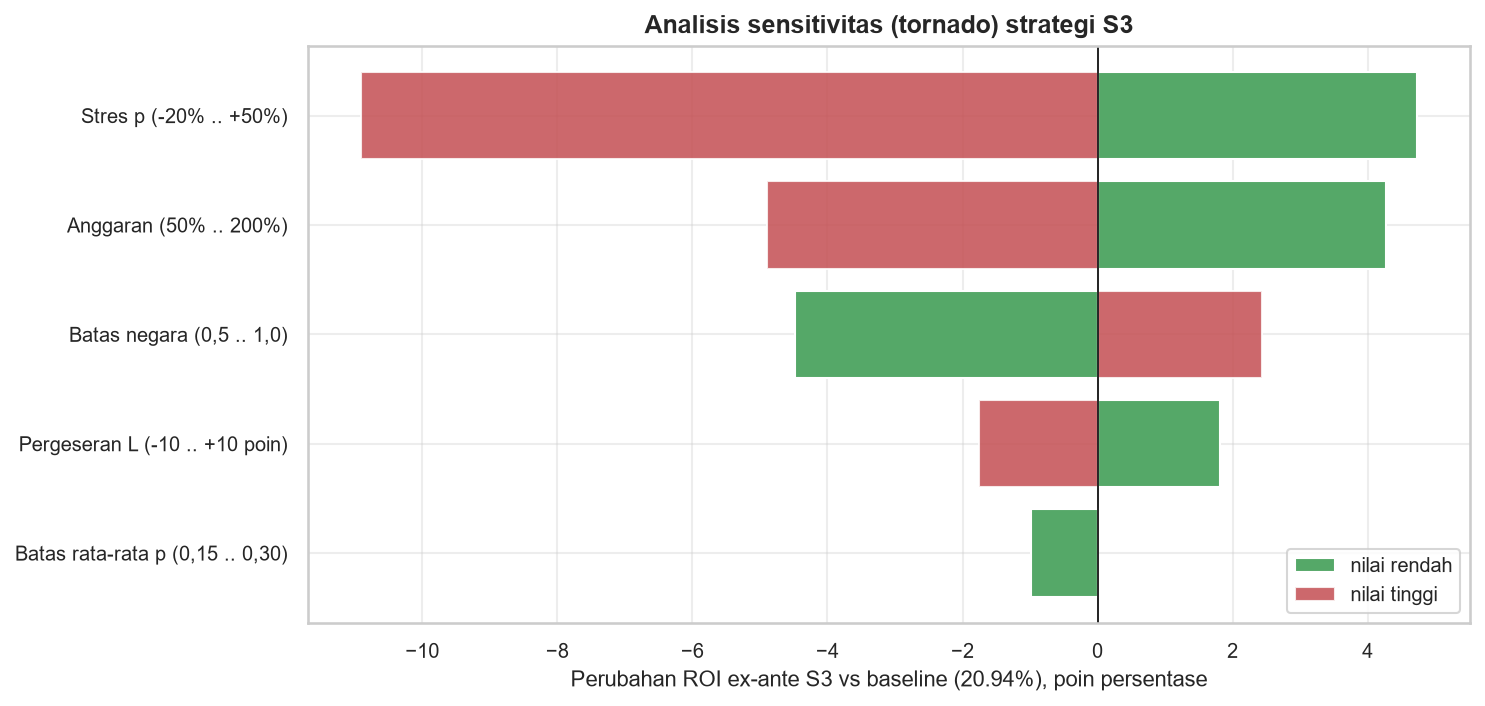

In [13]:
tor = pd.read_csv(T / "06_whatif_tornado.csv")
display(tor)
display(Image(filename=str(F / "06_whatif_tornado.png")))

**Dampak yang diperkirakan (berdasarkan asumsi; ROI ex-ante S3 dasar = 20,94%).**

- **Stres `p`:** −20% → ROI ex-ante 25,68%; +20% → 16,82%; +50% → 10,03% (profit 25.068 EUR). Ini adalah sensitivitas terbesar (−10,9 poin pada +50%). **Opsi terbaik tidak berubah** (tetap S3); portofolio tetap layak karena rata-rata `p` yang sudah ditekan masih dapat ≤ 0,20.
- **Pergeseran `L`:** −10 poin → 22,76%; +10 poin → 19,18% (± 1,8 poin). Sensitivitas terhadap `L` jauh lebih kecil daripada terhadap `p`.
- **Anggaran:** 50% → ROI 25,21% (profit 31.516 EUR); 200% → ROI 16,04% (profit 80.222 EUR). Menggandakan anggaran menaikkan profit absolut 53%, tetapi ROI turun 4,9 poin karena pinjaman terbaik habis lebih dulu (imbal hasil marjinal menurun).
- **Biaya diversifikasi (batas negara):** profit ex-ante 41.139 EUR (batas 0,5), 52.351 EUR (0,7), 58.455 EUR (1,0). Jadi batas 0,7 "membayar" **6.104 EUR** (≈ 10,4% profit tanpa batas) dan batas 0,5 membayar **17.316 EUR** dibandingkan tanpa batas.
- **Batas risiko:** `MAX_AVG_P` 0,15 → ROI 19,95%; untuk 0,20 sampai 0,30 hasilnya identik (20,94%) karena batas itu **tidak mengikat** (rata-rata `p` S3 = 0,179).
- Di seluruh 17 skenario, S3 tetap opsi terbaik di antara opsi yang patuh. S2 hanya menjadi patuh ketika batas negara dilonggarkan menjadi 1,0, itupun masih di bawah S3 secara ex-ante.

## 8. Skenario Platform (Langkah 6, sudut pandang tambahan)

Eksposur platform diasumsikan penuh pada tiap pinjaman yang disetujui (`ticket = Amount`), memakai fungsi ekonomi yang sama.

### 8.1 P1 — Kebijakan persetujuan (batas risiko `τ`)

Setujui pinjaman bila `p_calibrated ≤ τ`. Pilih `τ` yang memaksimalkan profit ex-ante dengan batasan: **tingkat persetujuan ≥ 40%** (analog *service level*) dan **rata-rata `p` disetujui ≤ 0,25**.

,tau,n_disetujui,tingkat_persetujuan,p_rata2_disetujui,default_rate_expost,total_pokok_eur,profit_exante_eur,roi_exante,profit_expost_eur,roi_expost,memenuhi_batasan,rekomendasi
0,0.1000,5195,0.0957,0.0574,0.0524,"11,087,097.0000","1,505,847.0655",0.1358,"1,511,466.0313",0.1363,False,Tidak
1,0.1500,9726,0.1792,0.0843,0.0674,"21,592,830.0000","2,525,520.0724",0.1170,"2,696,805.6969",0.1249,False,Tidak
2,0.2000,15929,0.2934,0.1178,0.0920,"37,045,810.0000","3,452,535.1646",0.0932,"4,058,432.1425",0.1096,False,Tidak
3,0.2500,22777,0.4196,0.1509,0.1211,"54,603,585.0000","3,823,524.7019",0.0700,"4,844,043.0616",0.0887,True,Ya
4,0.3000,27845,0.5130,0.1751,0.1443,"67,912,065.0000","3,697,160.8509",0.0544,"5,021,920.6846",0.0739,True,Tidak
5,0.3500,30488,0.5616,0.1883,0.1569,"75,171,564.0000","3,556,716.0398",0.0473,"5,160,166.0343",0.0686,True,Tidak
6,0.4000,32466,0.5981,0.1986,0.1657,"81,112,607.0000","3,345,020.4016",0.0412,"5,336,306.5918",0.0658,True,Tidak
7,0.4500,35523,0.6544,0.2183,0.1816,"90,783,144.0000","2,330,983.4829",0.0257,"5,200,552.3820",0.0573,True,Tidak
8,0.5000,40515,0.7464,0.2500,0.2039,"107,043,513.0000","-171,114.3988",-0.0016,"4,603,723.4990",0.0430,False,Tidak


Format tabel slide (opsi tau):

,tau,total_pokok_eur,tingkat_persetujuan,default_rate_expost,profit_exante_eur,profit_expost_eur,memenuhi_batasan,rekomendasi
2,0.2000,"37,045,810.0000",0.2934,0.0920,"3,452,535.1646","4,058,432.1425",False,Tidak
3,0.2500,"54,603,585.0000",0.4196,0.1211,"3,823,524.7019","4,844,043.0616",True,Ya
4,0.3000,"67,912,065.0000",0.5130,0.1443,"3,697,160.8509","5,021,920.6846",True,Tidak
6,0.4000,"81,112,607.0000",0.5981,0.1657,"3,345,020.4016","5,336,306.5918",True,Tidak


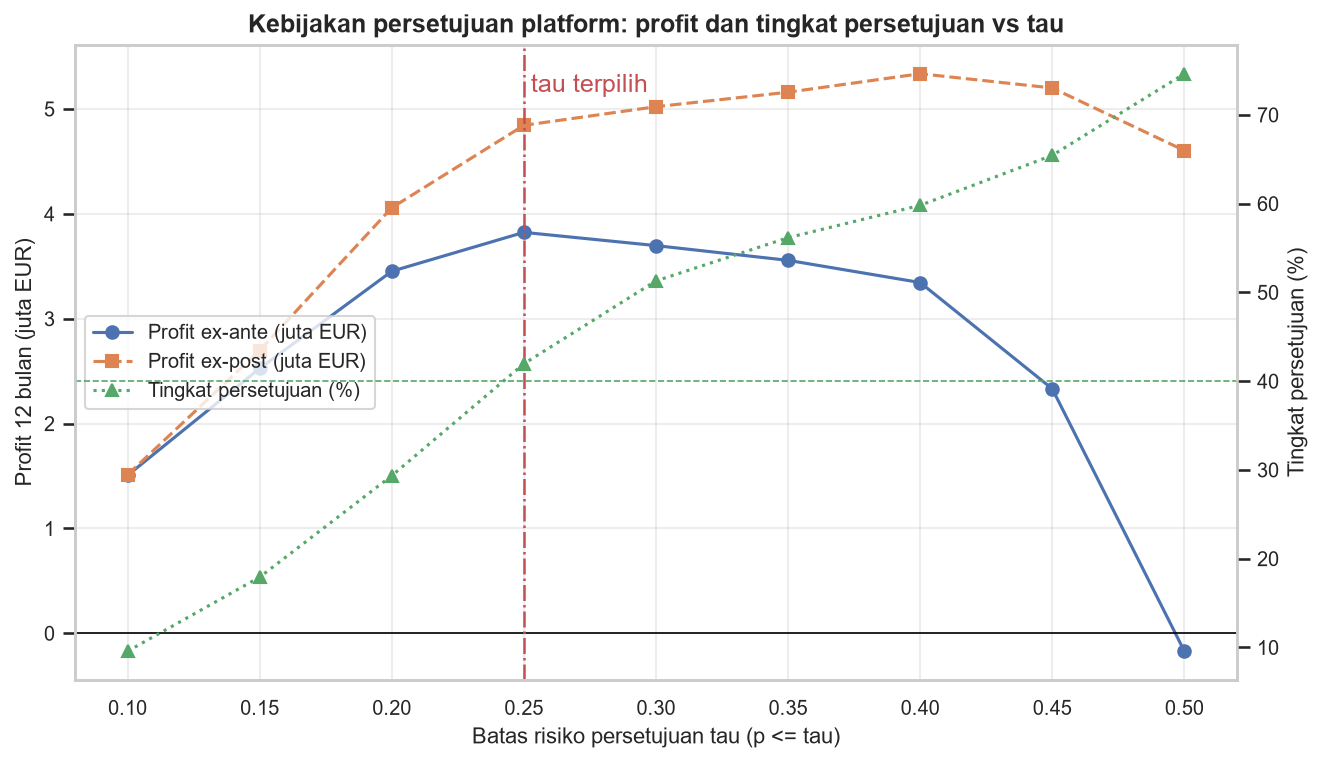

In [14]:
pol = pd.read_csv(T / "06_platform_threshold_policy.csv")
display(pol)
rec = pol[pol["rekomendasi"] == "Ya"].iloc[0]
assert len(pol[pol["rekomendasi"] == "Ya"]) == 1 and round(rec["tau"], 2) == 0.25
assert round(rec["tingkat_persetujuan"], 3) == 0.420

opsi_tau = pol[pol["tau"].isin([0.20, 0.25, 0.30, 0.40])][
    ["tau", "total_pokok_eur", "tingkat_persetujuan", "default_rate_expost", "profit_exante_eur", "profit_expost_eur", "memenuhi_batasan", "rekomendasi"]]
print("Format tabel slide (opsi tau):")
display(opsi_tau)
display(Image(filename=str(F / "06_platform_threshold_curve.png")))

**Rekomendasi P1 (berdasarkan asumsi):** `τ = 0,25` memberi profit ex-ante tertinggi di antara opsi yang memenuhi batasan: tingkat persetujuan **41,96%**, rata-rata `p` disetujui 0,151, default aktual 12,11%, total pokok 54,60 juta EUR, profit ex-ante **3,82 juta EUR** (ROI 7,00%) dan ex-post 4,84 juta EUR (ROI 8,87%). `τ = 0,20` memberi ROI lebih tinggi (9,32%) tetapi tingkat persetujuan hanya 29,3% (< 40%). Menaikkan `τ` ke 0,30 atau 0,40 menurunkan profit ex-ante (3,70 dan 3,35 juta EUR) meskipun profit ex-post naik: di `τ = 0,50` profit ex-ante menjadi **negatif** (−0,17 juta EUR). Selisih arah ex-ante vs ex-post ini lagi-lagi cerminan `p` yang dilebih-lebihkan; kebijakan yang bergantung pada level `p` perlu dikalibrasi ulang sebelum dipakai.

### 8.2 P2 — Penetapan bunga impas (*breakeven pricing*)

Untuk tiap pinjaman: `φ_i = interest12_frac_i ÷ (Interest_i/100)` dan bunga impas (dalam pendekatan linear) `r*_i = p_i·L ÷ ((1 − p_i)·φ_i)`, dalam persen. Pendekatan linear diverifikasi dengan menghitung ulang `interest12_frac` pada `r*_i` untuk 1.000 pinjaman acak dan melaporkan galat profit per EUR.

In [15]:
chk = pd.read_csv(T / "06_platform_breakeven_check.csv")
display(chk)
be = pd.read_csv(T / "06_platform_breakeven_pricing.csv")
for dim in ["Semua", "Country", "Rating", "Tenor"]:
    print(f"Persentase pinjaman dengan Interest < r* menurut {dim}")
    display(be[be["dimensi"] == dim].drop(columns="dimensi"))
sc = pd.read_csv(T / "06_platform_pricing_scenario.csv")
print(f"Skenario ilustratif: bunga dinaikkan hingga min(r*, Interest + {config.INTEREST_RAISE_CAP_PP:.0f} poin) pada pinjaman di bawah impas")
display(sc)

assert round(be.loc[be["dimensi"] == "Semua", "pct_di_bawah_impas"].iloc[0], 3) == 0.588
assert chk.loc[0, "n_sampel"] == 1000

,n_sampel,galat_u_rata2_abs,galat_u_median_abs,galat_u_p95_abs,galat_u_rata2_bertanda
0,1000,0.0061,0.0029,0.0222,0.0044


Persentase pinjaman dengan Interest < r* menurut Semua


,segmen,n_pinjaman,pct_di_bawah_impas,interest_median,r_star_median,selisih_median_pp
0,Semua,54283,0.5875,36.4700,33.7318,5.6322


Persentase pinjaman dengan Interest < r* menurut Country


,segmen,n_pinjaman,pct_di_bawah_impas,interest_median,r_star_median,selisih_median_pp
1,EE,27976,0.2959,25.2700,17.5538,-7.3611
2,ES,12662,0.8748,58.0900,85.4590,25.6508
3,FI,13645,0.9189,36.9000,72.6673,36.2712


...

,segmen,n_pinjaman,pct_di_bawah_impas,interest_median,r_star_median,selisih_median_pp
4,A,2030,0.5961,11.7500,15.1288,3.6039
5,AA,3550,0.7285,8.9700,15.1315,6.2526
6,B,3878,0.4593,16.0300,15.3498,-1.1664
7,C,7303,0.4048,22.8600,20.1529,-3.8722
8,D,10839,0.3575,32.0800,24.5938,-8.2751
9,E,15922,0.6585,38.9550,61.3489,24.5014
10,F,9608,0.8300,61.8600,85.8871,22.1646
11,HR,1153,0.8881,76.8900,85.3273,8.5303


Persentase pinjaman dengan Interest < r* menurut Tenor


,segmen,n_pinjaman,pct_di_bawah_impas,interest_median,r_star_median,selisih_median_pp
12,13-24,1765,0.2816,30.1700,13.4501,-10.0953
13,25-36,18539,0.5683,33.0200,31.8937,4.0995
14,37-48,2549,0.5575,38.0100,32.4581,4.4826
15,49-59,51,0.0588,46.9300,15.8310,-29.3454
16,60,30312,0.6223,36.7000,42.0657,8.5037
17,<=12,1067,0.5370,22.2800,23.1109,2.5352


Skenario ilustratif: bunga dinaikkan hingga min(r*, Interest + 10 poin) pada pinjaman di bawah impas


,segmen,n_dinaikkan,profit_exante_lama_eur,profit_exante_baru_eur,delta_profit_eur,total_pokok_eur
0,Semua,31892,"-8,406,938.9137","-4,154,804.9131","4,252,134.0007","144,311,951.0000"
1,Rating A,1210,"-170,749.9367","-1,440.8496","169,309.0871","4,741,650.0000"
2,Rating AA,2586,"-525,268.6704","-84,134.2445","441,134.4259","10,921,397.0000"
3,Rating B,1781,"49,822.8425","230,065.1172","180,242.2747","8,342,526.0000"
4,Rating C,2956,"-412,560.5730","-6,563.2140","405,997.3590","19,162,820.0000"
5,Rating D,3875,"-256,093.8162","338,527.3988","594,621.2151","29,146,799.0000"
6,Rating E,10485,"-4,635,642.9424","-3,063,525.9619","1,572,116.9804","47,369,822.0000"
7,Rating F,7975,"-2,371,461.7465","-1,517,016.5612","854,445.1853","23,633,799.0000"
8,Rating HR,1024,"-84,984.0710","-50,716.5978","34,267.4732","993,138.0000"


**Temuan P2 (berdasarkan asumsi).**

- Secara keseluruhan **58,8%** pinjaman memiliki `Interest < r*`. Menurut negara: Estonia 29,6%, Spanyol 87,5%, Finlandia **91,9%**. Menurut rating: AA 72,8% dan A 59,6% (bunga rendah), E 65,9%, F 83,0%, HR 88,8%. Menurut tenor: 60 bulan 62,2%, 13–24 bulan 28,2%.
- Galat pendekatan linear kecil: rata-rata |profit per EUR pada `r*`| = 0,0061 (median 0,0029; persentil 95 = 0,0222) pada 1.000 pinjaman acak, jadi `r*` cukup baik sebagai ukuran impas, bukan solusi eksak.
- **Skenario ilustratif:** menaikkan bunga (maks. +10 poin menuju `r*`) pada 31.892 pinjaman di bawah impas menaikkan profit ex-ante platform dari **−8,41 juta** menjadi **−4,15 juta EUR** (+4,25 juta EUR; total pokok 144,3 juta EUR). Profit tetap negatif, jadi harga saja tidak cukup pada asumsi ini.
- **Peringatan eksplisit:** skenario ini **mengabaikan efek kenaikan bunga terhadap permintaan dan risiko gagal bayar** (seleksi merugikan, *adverse selection*), sehingga manfaatnya kemungkinan **terlalu optimistis**. Median `r*` untuk Spanyol (85,5%) dan Finlandia (72,7%) juga jauh di atas bunga yang lazim, yang menunjukkan bahwa `p` dilebih-lebihkan dan daya urut dalam-negara lemah; angka ini adalah diagnostik, bukan rekomendasi harga.

## 9. Forecast Ringan (Langkah 7)

Deret bulanan (bulan penuh saja, 2016-01 s.d. 2021-06; Juli 2021 parsial dikecualikan): (a) jumlah dan total `Amount` pinjaman baru menurut `LoanDate`; (b) total `Amount` pinjaman yang masuk status default menurut bulan `DefaultDate` (arus default baru). Model: *seasonal naive* (lag 12, baseline) dan ETS aditif dengan tren teredam (musiman 12 bulan ditambahkan bila AIC lebih baik). Model dipilih per deret berdasarkan **evaluasi *rolling-origin* satu langkah** pada 6 bulan terakhir (Jan–Jun 2021): MAPE, sMAPE, dan **cakupan** interval 80% serta 95%.

> **Catatan horizon:** deret berakhir Juni 2021 dan Juli 2021 parsial, sehingga prakiraan 3 bulan "Agu–Okt 2021" membutuhkan empat langkah (Jul–Okt). Juli ikut disimpan untuk transparansi tetapi tidak dievaluasi; pembahasan memakai Agu–Okt.

In [16]:
ser = pd.read_csv(T / "06_forecast_series.csv", parse_dates=["month"])
print(f"Deret: {ser['month'].min():%Y-%m} s.d. {ser['month'].max():%Y-%m}, {len(ser)} bulan")
display(ser.tail(6))
bt = pd.read_csv(T / "06_forecast_backtest.csv")
display(bt)
fv = pd.read_csv(T / "06_forecast_values.csv", parse_dates=["month"])
display(fv)

assert len(ser) == 66 and ser["month"].max() == pd.Timestamp("2021-06-01")
assert bt.groupby("serie")["dipilih"].sum().eq(1).all()

Deret: 2016-01 s.d. 2021-06, 66 bulan


,month,n_loans,amount_loans,amount_default
60,2021-01-01,"2,211.0000","6,115,439.0000","3,757,863.0000"
61,2021-02-01,"2,388.0000","6,376,721.0000","3,579,222.0000"
62,2021-03-01,"2,709.0000","7,548,599.9700","4,226,756.0000"
63,2021-04-01,"3,387.0000","9,121,137.7100","4,316,513.0000"
64,2021-05-01,"3,886.0000","10,341,560.6100","2,894,619.0000"
65,2021-06-01,"4,271.0000","10,977,198.9700","2,693,750.0000"


,serie,model,n_uji,mape_pct,smape_pct,cakupan_80,cakupan_95,ets_musiman_aic,dipilih
0,n_loans,seasonal_naive,6,82.7060,83.4558,0.6667,1.0000,NaN,False
1,n_loans,ets,6,12.3317,12.5003,1.0000,1.0000,False,True
2,amount_loans,seasonal_naive,6,84.5004,94.6268,0.6667,1.0000,NaN,False
3,amount_loans,ets,6,12.7012,12.4524,1.0000,1.0000,False,True
4,amount_default,seasonal_naive,6,63.0775,56.3714,0.1667,0.6667,NaN,False
5,amount_default,ets,6,24.6323,21.1160,0.6667,1.0000,False,True


,serie,model,month,mean,lo80,hi80,lo95,hi95,ets_musiman_aic
0,n_loans,ets,2021-07-01,"4,636.4933","3,896.3479","5,376.6386","3,504.5386","5,768.4479",False
1,n_loans,ets,2021-08-01,"4,983.4384","3,979.4734","5,987.4034","3,448.0065","6,518.8704",False
2,n_loans,ets,2021-09-01,"5,260.9946","3,903.1642","6,618.8249","3,184.3723","7,337.6169",False
3,n_loans,ets,2021-10-01,"5,483.0395","3,733.7324","7,232.3466","2,807.7052","8,158.3738",False
4,amount_loans,ets,2021-07-01,"11,610,459.7423","9,492,512.4699","13,728,407.0147","8,371,338.9088","14,849,580.5757",False
5,amount_loans,ets,2021-08-01,"12,123,800.3081","9,043,578.7483","15,204,021.8679","7,413,007.9499","16,834,592.6663",False
6,amount_loans,ets,2021-09-01,"12,534,472.7608","8,431,762.5995","16,637,182.9220","6,259,919.0314","18,809,026.4902",False
7,amount_loans,ets,2021-10-01,"12,863,010.7229","7,727,495.0909","17,998,526.3550","5,008,917.3322","20,717,104.1136",False
8,amount_default,ets,2021-07-01,"3,166,678.6230","2,061,343.1650","4,272,014.0809","1,476,213.9186","4,857,143.3273",False
9,amount_default,ets,2021-08-01,"3,071,348.1894","1,885,208.0000","4,257,488.3788","1,257,303.3126","4,885,393.0662",False


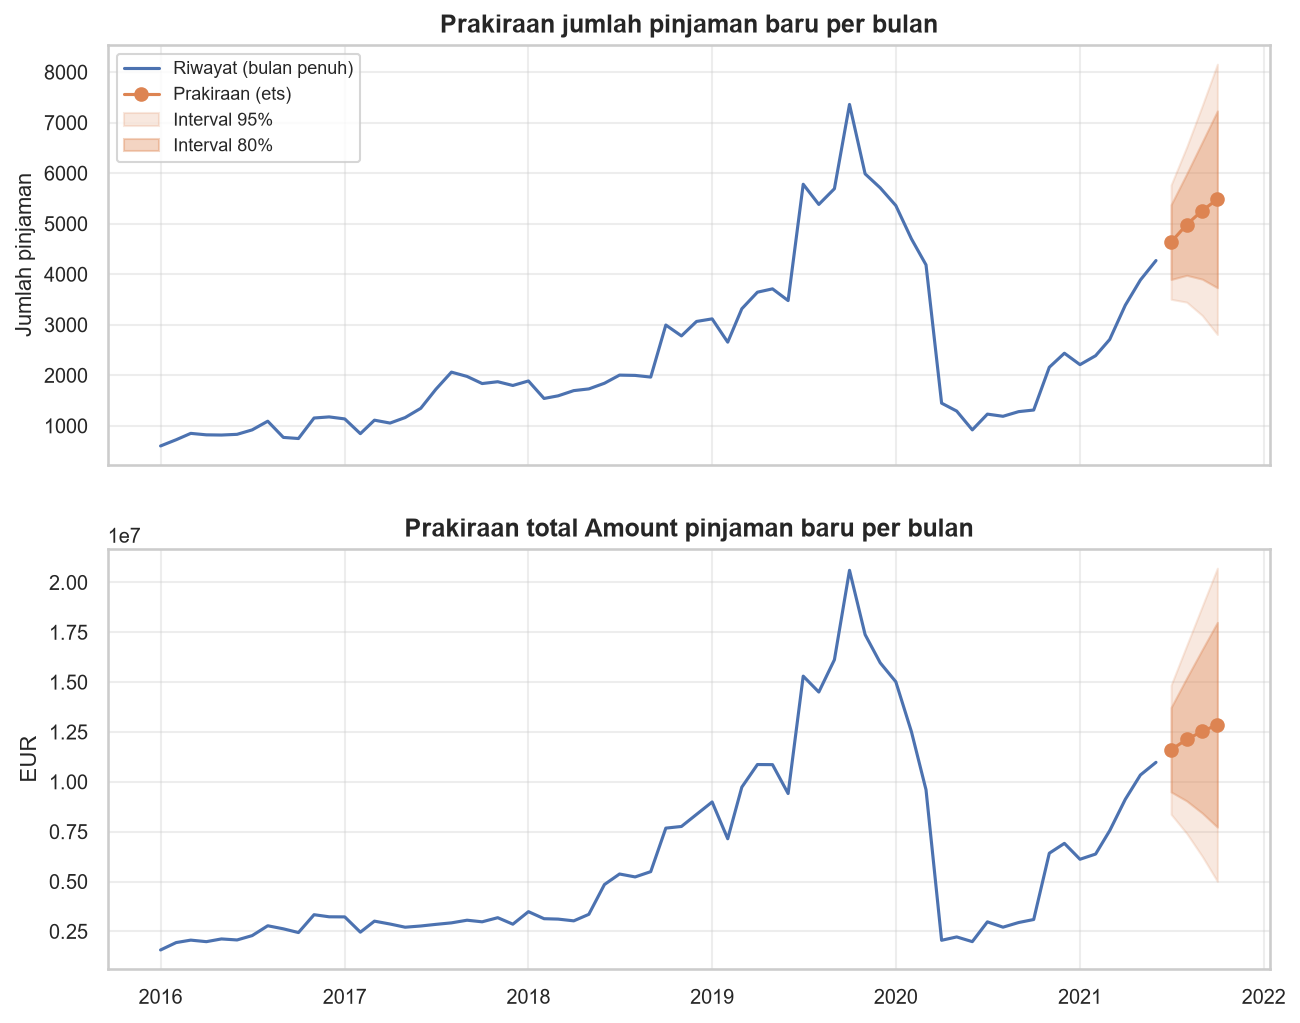

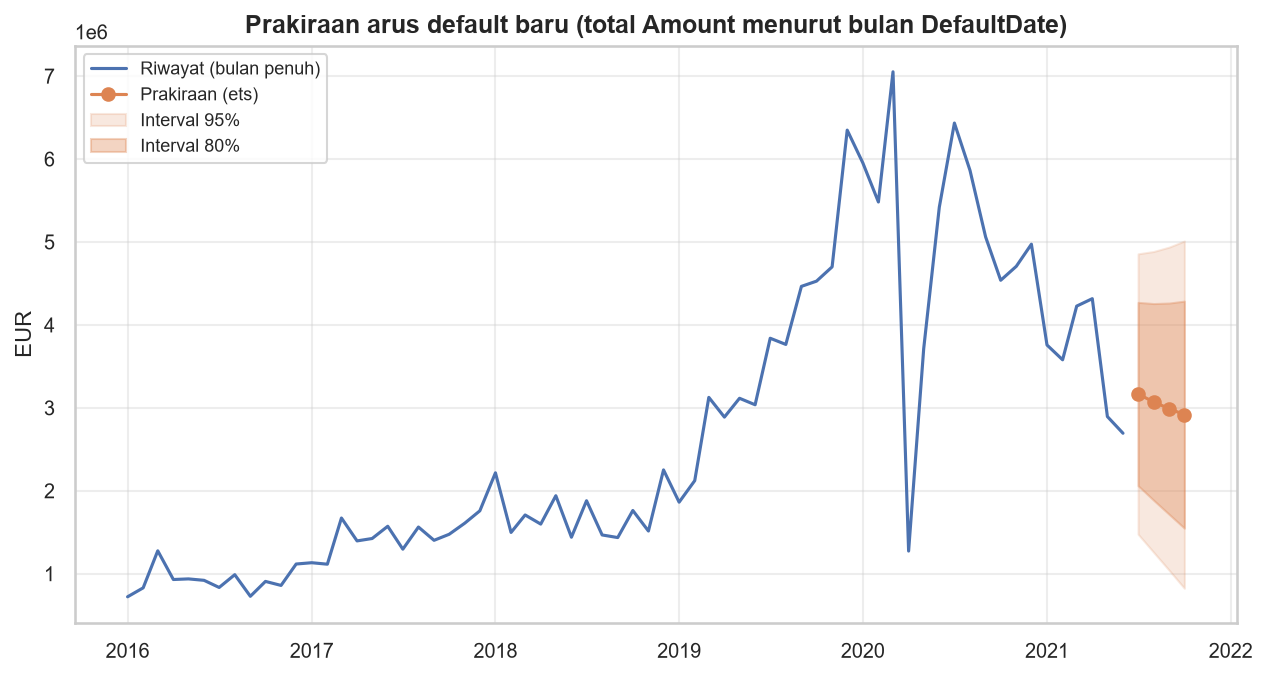

In [17]:
display(Image(filename=str(F / "06_forecast_volume.png")))
display(Image(filename=str(F / "06_forecast_defaults.png")))

**Hasil forecast (berdasarkan model dan data yang ada).**

- **Pemilihan model:** ETS dipilih untuk ketiga deret (tanpa musiman menurut AIC). MAPE ETS 12,3% (jumlah pinjaman), 12,7% (total `Amount`), dan 24,6% (arus default), jauh lebih baik daripada *seasonal naive* (82,7%; 84,5%; 63,1%) karena deret mengalami patahan struktural, sehingga pola tahun lalu tidak berlaku.
- **Cakupan interval** (hanya **6** titik uji, sehingga **tidak konklusif**): jumlah pinjaman 100% (80%) dan 100% (95%); total `Amount` 100% dan 100%; arus default 66,7% dan 100%.
- **Prakiraan Agu–Okt 2021 (interval 80%):** jumlah pinjaman 4.983 (3.979–5.987), 5.261 (3.903–6.619), 5.483 (3.734–7.232); total `Amount` 12,12 / 12,53 / 12,86 juta EUR; arus default baru 3,07 / 2,99 / 2,92 juta EUR (interval 80% 1,89–4,26; 1,71–4,26; 1,55–4,29 juta EUR).

### 9.1 Keterkaitan dengan keputusan investor

In [18]:
link = pd.read_csv(T / "06_forecast_decision_link.csv")
display(link)
s3_share = meta["s3_share_of_opportunity_set"]
print(f"Proporsi pinjaman uji yang dipilih S3: {s3_share:.4f} ({5000:,} dari {opp['n']:,})")

assert round(s3_share, 4) == 0.0921
assert 9 < link["bulan_untuk_mencapai_N"].min() < link["bulan_untuk_mencapai_N"].max() < 12

,bulan,prakiraan_pinjaman,lo80,hi80,share_lolos_S3,lolos_per_bulan,lolos_lo80,lolos_hi80,MIN_LOANS,N_target,bulan_untuk_mencapai_N,bulan_untuk_mencapai_MIN_LOANS
0,2021-08,"4,983.4384","3,979.4734","5,987.4034",0.0921,459.0239,366.5488,551.4989,2000,5000,10.8927,4.3571
1,2021-09,"5,260.9946","3,903.1642","6,618.8249",0.0921,484.5895,359.5199,609.6591,2000,5000,10.3180,4.1272
2,2021-10,"5,483.0395","3,733.7324","7,232.3466",0.0921,505.0420,343.9136,666.1705,2000,5000,9.9002,3.9601


Proporsi pinjaman uji yang dipilih S3: 0.0921 (5,000 dari 54,283)


*Kecukupan arus pinjaman.* Proporsi pinjaman yang lolos kriteria S3 pada backtest adalah **9,21%** (5.000 dari 54.283 pinjaman uji). Dikalikan prakiraan jumlah pinjaman per bulan, diperkirakan hanya **≈ 459–505 pinjaman per bulan** yang memenuhi syarat (interval 80%: 344–666). Dengan demikian `MIN_LOANS = 2.000` baru tercapai dalam **≈ 4,0–4,4 bulan** dan target `N = 5.000` dalam **≈ 9,9–10,9 bulan**: **anggaran 250.000 EUR tidak dapat dideploy dalam satu bulan; diperlukan sekitar 10 bulan** bila kriteria S3 dijaga (dengan asumsi kualitas pinjaman baru serupa dengan periode uji). *Skenario dasar kerugian:* arus default baru yang diprakirakan (≈ 2,9–3,1 juta EUR per bulan) menjadi konteks bagi skenario stres `p` pada Bagian 7; prakiraan yang turun dibanding Juni 2021 (2,69 juta EUR) hanyalah ekstrapolasi tren teredam, bukan bukti perbaikan kualitas kredit.

**Keterbatasan forecast:** data berakhir 20 Juli 2021; deret mengalami **patahan struktural** (puncak 2019, penurunan 2020–2021, lalu pemulihan); prakiraan ETS meneruskan tren naik terbaru dan sangat sensitif terhadap pemulihan tersebut; hanya 6 titik uji. Prakiraan ini adalah **ilustrasi metode**, bukan ramalan andal.

## 10. Ringkasan Temuan Prescriptive

1. **Rekomendasi investor (berdasarkan asumsi parameter awal): S3** (optimasi berbatas) — satu-satunya dari enam opsi yang memenuhi seluruh batasan, dengan ROI ex-ante **20,94%** dan ex-post **19,01%** (CI profit ex-post 44.315–50.641 EUR) pada anggaran 250.000 EUR.
2. **Opsi yang lebih "menarik" tetapi tidak boleh direkomendasikan:** S2 (ROI ex-post 14,53%, default 5,12%) melanggar batas negara (100% Estonia); S4 dan S1 juga melanggar batas negara.
3. **Peringatan pengejar bunga (S5):** default aktual **56,70%**, ROI ex-post **−9,67%** — bunga tinggi tidak menutup risiko.
4. **Ex-ante vs ex-post:** `p` dilebih-lebihkan ± 6 poin (33,0% vs 26,8%) membuat ROI ex-ante S0/S1 negatif padahal ex-post positif. Baca rekomendasi sebagai **perbandingan antar-opsi**, bukan level ROI.
5. **Kendala yang mengikat:** anggaran dan batas negara Estonia (70%); rating F+HR (22,9% dari 25%) dan rata-rata `p` (0,179 dari 0,20) hampir mengikat; solver mengonfirmasi optimal (relaksasi LP integral, 54.283 variabel).
6. **Biaya diversifikasi:** batas negara 0,7 "membayar" ≈ 6.104 EUR profit ex-ante (≈ 10,4%) dibanding tanpa batas; batas 0,5 membayar ≈ 17.316 EUR.
7. **Sensitivitas:** stres `p` +50% menurunkan ROI ex-ante S3 menjadi 10,03% (−10,9 poin); pergeseran `L` ± 10 poin hanya ± 1,8 poin; pada seluruh 17 skenario S3 tetap opsi terbaik di antara opsi yang patuh.
8. **Skala anggaran:** menggandakan anggaran menaikkan profit 53% tetapi menurunkan ROI dari 20,94% ke 16,04%.
9. **Platform (P1):** `τ = 0,25` memberi profit ex-ante tertinggi dengan tingkat persetujuan 41,96% (profit ex-ante 3,82 juta EUR); di `τ = 0,50` profit ex-ante negatif.
10. **Platform (P2):** 58,8% pinjaman berbunga di bawah impas (Finlandia 91,9%, Spanyol 87,5%, Estonia 29,6%); menaikkan bunga (maks. +10 poin) memperbaiki profit ex-ante +4,25 juta EUR tetapi tetap negatif dan mengabaikan efek permintaan.
11. **Forecast:** ETS terpilih (MAPE 12,3% untuk jumlah pinjaman); prakiraan Agu–Okt 2021 ≈ 5.000–5.500 pinjaman per bulan (interval 80% lebar).
12. **Hubungan forecast–keputusan:** hanya ≈ 459–505 pinjaman per bulan memenuhi kriteria S3, sehingga deployment penuh anggaran memerlukan **≈ 10 bulan**.

### Rekomendasi dan Dampak yang Diperkirakan
**Rekomendasi:** *berdasarkan asumsi parameter awal, opsi S3 memberikan hasil terbaik: mendanai 5.000 pinjaman (tiket 50 EUR) dengan komposisi hasil optimasi untuk memaksimalkan keuntungan dengan tetap menjaga batasan rata-rata `p` ≤ 0,20, eksposur negara ≤ 70%, rating F+HR ≤ 25%, dan tenor 60 bulan ≤ 70%.* **Dampak yang diperkirakan:** profit 12 bulan ≈ 52.351 EUR secara ex-ante (ROI 20,94%) dan ≈ 47.520 EUR ex-post (ROI 19,01%), dengan deployment bertahap sekitar 10 bulan mengikuti arus pinjaman yang memenuhi syarat. Untuk platform: kebijakan `τ = 0,25` (persetujuan ≈ 42%).

### Keterbatasan
- **Pelebih-lebihan `p`** (± 6 poin) dan **daya urut dalam-negara yang lemah** (Finlandia AUC 0,55; Spanyol 0,58): sebagian keunggulan S3 berasal dari perbedaan antar-negara; level ROI mutlak tidak andal.
- **Asumsi bunga sederhana** tanpa reinvestasi, tanpa biaya platform/pajak; `interest12_frac` menyimpang sistematis dari `MonthlyPayment` (median selisih absolut 7,9%) dan komposisi S3 sensitif terhadap definisi pendapatan bunga (irisan 75,4%).
- **Kerugian konstan `L = 0,731`**, konservatif; tidak membedakan segmen atau waktu pemulihan.
- **Bias populasi:** backtest hanya pada pinjaman yang masuk dan didanai pada 2019-07 s.d. 2020-07 (periode pandemi), hasil 12 bulan yang teramati; investor tidak bisa mendanai seluruh pinjaman yang ada (kapasitas pasar dan persaingan tidak dimodelkan).
- **Model prediktif tidak dilatih ulang** dan efek keputusan terhadap permintaan/risiko (elastisitas bunga, seleksi merugikan) di luar cakupan.
- **Forecast** hanya ilustrasi metode (patahan struktural, 6 titik uji).